# prior_experiment_training

## README

This notebook does not train from the base model. It trains on an **adapter that `run_experiment.ipynb` created**:
every run here loads that run's saved LoRA adapter (and its AdamW state, when it was saved) at one checkpoint, and
trains on from there over its own settings file's data, as a new run with its own id.

The difference from `run_experiment.ipynb`, and the only one:

| | `run_experiment.ipynb` | `prior_experiment_training.ipynb` |
|---|---|---|
| starts from | the base model (from scratch) | `ADAPTER`: a run and one of its decision checkpoints |
| settings files | one, `SETTINGS_FILE` | a list, `CONFIG_FILES`, trained one after another |

The machine setup and checks are the same cells as `run_experiment.ipynb`, and each run prints the same plan before
it trains. On top of those, a check cell confirms the adapter is on disk and that every settings file loads, fits the
adapter (same model, quantization and LoRA shape) and matches its data, **before** any training starts.

Edit the first code cell and nothing else: the adapter, the list of settings files, and optionally a last step and
checkpoint spacing applied to all of them. Then run the cells top to bottom. Each finished run is pushed to the Hub.
With `SWEEP` named, progress is kept in `results/queue/<SWEEP>/status.json`: running the run cell again skips the
runs that finished and starts over any that failed or were cut off.

So: run the experiment in `run_experiment.ipynb` first, then use this notebook to train on from its adapter.

In [1]:
# The adapter every run starts from: a run that run_experiment.ipynb made, and a decision step it saved a
# checkpoint at. It must be on disk at checkpoints/<run_id>/decision/step-<step>/ (the check cell lists
# what is there). Each run trains steps step+1 .. training_steps of its own settings file, as a new run.
# None: use the start_from written in each settings file instead.
ADAPTER = {"run_id": "20261106-152354_paper_minimum_threshold_Qwen3-8B", "step": 1500}

# The settings files to train, one run each, in this order. Any file in configs/ works if it keeps
# introspection_training false (start_from trains decisions only). baseline_before_training is
# switched off for you: there is no untrained model to score.
CONFIG_FILES = [
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w75_c25.json",
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w65_c35.json",
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w55_c45.json",
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w45_c55.json",
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w35_c65.json",
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w25_c75.json",
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w15_c85.json",
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w05_c95.json",
    "configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_w00_c100.json",
]

# Applied to every file above when set; None keeps each file's own training_steps / checkpoint_every.
END_STEP = None              # e.g. 3000: train to decision step 3000
CHECKPOINT_EVERY = None      # e.g. 100: score and save every 100 steps

# A name for this batch of runs. Progress goes to results/queue/<SWEEP>/status.json, so re-running the
# run cell skips finished runs; the Results cells read it. None: no progress file, every file runs.
SWEEP = "cut_sweep"

# The branch of the repo to run. On a fresh machine it is cloned; an existing clone is moved
# onto it and brought up to date, so the code is always this branch's latest commit.
BRANCH = "bootstrap-ci"

# Where finished runs are saved so they survive the machine. Must be a Hub repo you
# can write to; the owner must match the account your token belongs to.
HUB_REPO = "adamchanna/bdp-plunkett-qwen3"

# Settings files for this notebook:
#   configs/minimum_threshold_one_persona/cut_sweep/persona_a/cut_sweep_wXX_cYY.json  (and _24gb)
#                                    the cut sweep: XX% of trials decided by the weights, YY% by the cut,
#                                    over data/minimum_threshold_one_persona/cut_sweep/persona_a/wXX_cYY/. Written by
#                                    scripts/make_cut_sweep.py (re-run it to change the shares, end step or spacing).
#   any other file in configs/       trained on from ADAPTER the same way, if its model, quantization
#                                    and LoRA shape match the adapter's run (the check cell says).

## Set up the machine

In [2]:
!nvidia-smi || echo "no nvidia-smi: CPU-only machine, these runs need a GPU"

Sat Nov  7 11:42:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.88                 KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti   WDDM  |   00000000:01:00.0  On |                  N/A |
|  0%   38C    P8              9W /  300W |     850MiB /  16303MiB |      4%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# Clone BRANCH when the code is not already here, or move an existing clone onto it, then pin versions.
# run_me.py runs before the install: it re-pins requirements to whatever this machine
# already ships, keeping its CUDA-matched torch instead of letting pip swap it out.
import os, subprocess, sys

CLONE_URL = "https://github.com/Bilal-Trigui/Decision_Task_Database_Experiments.git"
if not os.path.exists("src"):
    if not os.path.exists("Decision_Task_Database_Experiments"):
        subprocess.run(["git", "clone", "-b", BRANCH, CLONE_URL], check=True)
    os.chdir("Decision_Task_Database_Experiments")
# An existing clone may sit on another branch or an older commit. This refuses rather than
# overwrite local edits: commit or stash them, or set BRANCH to the branch they are on.
subprocess.run(["git", "fetch", "origin", BRANCH], check=True)
subprocess.run(["git", "checkout", BRANCH], check=True)
subprocess.run(["git", "pull", "--ff-only", "origin", BRANCH], check=True)
commit = subprocess.run(["git", "log", "-1", "--format=%h %s"], capture_output=True, text=True).stdout.strip()
print(f"code: branch {BRANCH}, commit {commit}")
subprocess.run([sys.executable, "run_me.py"], check=True)

# Keep model downloads in one folder, easy to delete on a shared disk.
os.environ.setdefault("HF_HOME", os.path.abspath("hf_cache"))
# Let the CUDA allocator grow segments instead of fragmenting. Must be set before
# torch initialises CUDA, which is why it lives here and not in the GPU check.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
print("repo ready in", os.getcwd())

code: branch bootstrap-ci, commit f86b6a8 Data: 100 trials per persona, 60% decided by the weights
repo ready in C:\Users\PunchCat\adam_experiment\Decision_Task_Database_Experiments


In [4]:
# %pip installs into THIS kernel's environment. A pip subprocess can land packages
# somewhere the kernel cannot import from, which surfaces later as ModuleNotFoundError.
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\PunchCat\adam_experiment\Decision_Task_Database_Experiments\.venv\Scripts\python.exe -m pip install --upgrade pip


In [5]:
# Confirm the kernel can import what the pipeline needs.
#
# On JupyterHub, pip usually installs into the user site-packages, and a kernel
# that started before that folder existed does not have it on sys.path. That is
# the normal cause of ModuleNotFoundError straight after a successful install.
# Adding the folder here repairs it without a restart.
import importlib, importlib.util, os, site, sys

user_site = site.getusersitepackages()
if user_site and os.path.isdir(user_site) and user_site not in sys.path:
    sys.path.append(user_site)
    importlib.invalidate_caches()
    print("added user site-packages to sys.path:", user_site)

print("kernel python:", sys.executable)
needed = ("numpy", "pandas", "sklearn", "matplotlib", "torch", "transformers", "peft", "huggingface_hub")
missing = [m for m in needed if importlib.util.find_spec(m) is None]
if missing:
    print("MISSING:", missing)
    print("Restart the kernel (Kernel -> Restart Kernel), run the install cell, then this cell again.")
else:
    print("all imports available")

kernel python: C:\Users\PunchCat\adam_experiment\Decision_Task_Database_Experiments\.venv\Scripts\python.exe
all imports available


In [6]:
# Confirm the GPU matches what the settings assume. bf16 needs Ampere or newer:
# the 20gb configs ask for it and the loader refuses rather than falling back.
import torch

print("torch", torch.__version__)
if torch.cuda.is_available():
    print("gpu", torch.cuda.get_device_name(0))
    print("vram GB", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
    print("bf16 supported", torch.cuda.is_bf16_supported())
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    if vram < 30:
        print(f"\nThis is a MIG slice of about {vram:.0f} GB, not a whole card.")
        print("Use the *_20gb configs for 4B and 8B. 14B will not fit here.")
    elif vram < 60:
        print(f"\nThis is a MIG slice of about {vram:.0f} GB. The *_20gb configs fit with room to spare.")
else:
    print("no CUDA device: these runs need a GPU")

torch 2.8.0+cu128
gpu NVIDIA GeForce RTX 5070 Ti
vram GB 17.1
bf16 supported True

This is a MIG slice of about 17 GB, not a whole card.
Use the *_20gb configs for 4B and 8B. 14B will not fit here.


In [7]:
# Credentials. Typed rather than written into a cell, so nothing lands in git or in
# a saved notebook. Needed only for the save cells; the public Qwen3 weights do not
# require a token.
#
# A token that the Hub rejects is discarded and you are asked again, so a typo or
# a revoked token never gets stuck in the environment.
import getpass, os
from huggingface_hub import HfApi
from huggingface_hub.utils import HfHubHTTPError

owner = HUB_REPO.split("/")[0]
who = None
for attempt in range(3):
    token = os.environ.get("HF_TOKEN") or getpass.getpass("Hugging Face WRITE token (blank to skip): ")
    if not token:
        break
    try:
        who = HfApi(token=token).whoami()
        os.environ["HF_TOKEN"] = token
        break
    except HfHubHTTPError as err:
        os.environ.pop("HF_TOKEN", None)
        if err.response is not None and err.response.status_code == 401:
            print("The Hub rejected that token (401). Check it is a WRITE token and not revoked. Try again.")
            continue
        raise

if who is None:
    print("no token: the run works, but saving refuses and nothing survives the machine")
else:
    allowed = [who["name"]] + [o["name"] for o in who.get("orgs", [])]
    print("token belongs to:", who["name"])
    if owner in allowed:
        print(f"HUB_REPO owner '{owner}' matches. Saving will work.")
    else:
        print(f"MISMATCH: HUB_REPO starts with '{owner}' but this token can only write to {allowed}.")
        print(f"Set HUB_REPO = \"{who['name']}/bdp-plunkett-qwen3\" in the first cell and re-run it.")

C:\Users\PunchCat\adam_experiment\Decision_Task_Database_Experiments\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Hugging Face WRITE token (blank to skip):  ········


token belongs to: adamchanna
HUB_REPO owner 'adamchanna' matches. Saving will work.


## Check the adapter and every settings file

Nothing trains here. It confirms the adapter is on disk, then loads each settings file with `ADAPTER`,
`END_STEP` and `CHECKPOINT_EVERY` applied, and checks that it validates, that the adapter fits it (same model,
quantization, finetune and LoRA shape as the run that made it), that its data folder matches its rule, and that the
disk has room. The run cell refuses to start until this cell has passed with the current settings.

In [8]:
import json, shutil
from pathlib import Path
from src.config import resolve
from src.rules.base import check_manifest
from src.pipeline import branch_checkpoint
from src.experiments import load_experiment, disk_needed_gb, Status

START_FROM = (ADAPTER["run_id"], ADAPTER["step"]) if ADAPTER else None
CONFIG_FILES = [str(c) for c in CONFIG_FILES]

if ADAPTER:
    run_ckpts = Path("checkpoints") / ADAPTER["run_id"] / "decision"
    on_disk = sorted((p.name for p in run_ckpts.glob("step-*")), key=lambda s: int(s.split("-")[1]))
    print(f"adapter       {ADAPTER['run_id']} step {ADAPTER['step']}")
    print(f"on disk       {', '.join(on_disk) if on_disk else 'NO checkpoints of this run under ' + str(run_ckpts)}")
    src_settings = Path("results") / ADAPTER["run_id"] / "settings.json"
    if src_settings.exists():
        smh = json.loads(src_settings.read_text())["model_hyperparameters"]
        print(f"made by       {smh['model_name']}, {smh['quantization']}, {smh['finetune']} rank {smh.get('lora_rank')}, "
              f"trained to step {smh['training_steps']}")
    else:
        print(f"made by       unknown: {src_settings} is missing, so the model/LoRA match can't be checked")
else:
    print("adapter       None: each settings file's own start_from")

status = Status(SWEEP).data if SWEEP else {"runs": []}
done = {r["config"]: r.get("run_id") for r in status["runs"] if r.get("status") == "done"}

problems, need_gb = {}, 0.0
print()
for config in CONFIG_FILES:
    try:
        cfg = load_experiment(config, START_FROM, END_STEP, CHECKPOINT_EVERY)
        mh = cfg["model_hyperparameters"]
        if not mh["start_from"]:
            raise ValueError("no adapter: ADAPTER is None and this file has no start_from (that is run_experiment.ipynb's job)")
        ckpt = branch_checkpoint(cfg)
        check_manifest(cfg["model_training"]["data_dir"], resolve(cfg).rule, cfg)
        if config in done:
            note = f"already done ({done[config]}), will be skipped"
        else:
            need_gb += disk_needed_gb(cfg)
            note = f"steps {mh['start_from']['step'] + 1}-{mh['training_steps']}, every {mh['checkpoint_every']}"
        print(f"  ok      {config:42} {note}")
    except Exception as err:
        problems[config] = f"{type(err).__name__}: {err}"
        print(f"  PROBLEM {config:42} {problems[config]}")

free_gb = shutil.disk_usage(".").free / 1024 ** 3
print(f"\ndisk          about {need_gb:.1f} GB needed for the runs still to do, {free_gb:.1f} GB free")
if free_gb < need_gb:
    problems["disk"] = f"{free_gb:.1f} GB free, about {need_gb:.1f} GB needed"
    print("NOT ENOUGH DISK: free space, push and delete old checkpoints, or set save_optimizer 'last'")

PREFLIGHT_PASSED = (not problems, ADAPTER, list(CONFIG_FILES), END_STEP, CHECKPOINT_EVERY)
print("\nall checks passed: go on to the run cell" if not problems
      else f"\n{len(problems)} problem(s): fix them (or drop those files from CONFIG_FILES) and run this cell again")

adapter       20261106-152354_paper_minimum_threshold_Qwen3-8B step 1500
on disk       step-1500
made by       Qwen/Qwen3-8B, 4bit, lora rank 8, trained to step 10000

  ok      configs/cut_sweep_w75_c25.json             steps 1501-3000, every 100
  ok      configs/cut_sweep_w65_c35.json             steps 1501-3000, every 100
  ok      configs/cut_sweep_w55_c45.json             steps 1501-3000, every 100
  ok      configs/cut_sweep_w45_c55.json             steps 1501-3000, every 100
  ok      configs/cut_sweep_w35_c65.json             steps 1501-3000, every 100
  ok      configs/cut_sweep_w25_c75.json             steps 1501-3000, every 100
  ok      configs/cut_sweep_w15_c85.json             steps 1501-3000, every 100
  ok      configs/cut_sweep_w05_c95.json             steps 1501-3000, every 100
  ok      configs/cut_sweep_w00_c100.json            steps 1501-3000, every 100

disk          about 17.9 GB needed for the runs still to do, 26.7 GB free

all checks passed: go on to the run 

## Run the experiments

Each settings file in `CONFIG_FILES` is trained in turn, starting from `ADAPTER`. Before each one trains, the cell
prints the same plan `run_experiment.ipynb` does (the rule, the model, the decision steps, introspection, learning
rate, questions, estimation, eval batches), plus where it starts from and the disk it needs; then the training log.
Check the first plan before walking away.

Each run is pushed to the Hub as soon as it finishes. One run failing is reported and the rest still run.
Stopping the cell (or the machine sleeping) cuts the run in progress off: run the cell again and, with `SWEEP` set,
the finished runs are skipped and the cut-off one starts over from the adapter.

In [9]:
from src.pipeline import run
from src.config import estimation_counts, eval_batch_size, introspection_points
from src.experiments import load_experiment, disk_needed_gb, free_gpu, Status, _gpu_taken
from src.persist import push_run
import os, shutil, traceback
from datetime import datetime
from pathlib import Path

assert "PREFLIGHT_PASSED" in globals() and PREFLIGHT_PASSED == (True, ADAPTER, [str(c) for c in CONFIG_FILES], END_STEP, CHECKPOINT_EVERY), \
    "run the check cell above (with these settings) and fix what it reports first"


def print_plan(cfg):
    """The plan run_experiment.ipynb prints before training, plus where the run starts from."""
    mh, rule = cfg["model_hyperparameters"], cfg["decision_rule"]
    points = introspection_points(cfg)
    print(f"settings      {cfg['_source']}")
    print(f"rule          {rule['type']}, {rule['option_count']} options, data {cfg['model_training']['data_dir']}")
    print(f"model         {mh['model_name']}, {mh['quantization']}, {cfg['compute']['mixed_precision']} on {cfg['compute']['device']}")
    print(f"decisions     {mh['training_steps']} steps, a checkpoint every {mh['checkpoint_every']}, "
          f"baseline {'on' if mh['baseline_before_training'] else 'off'}")
    print(f"introspection " + (f"from decision steps {points}, {mh['introspection_steps']} steps per fold, "
                               f"targets {mh['introspection_targets']}"
                               + (", decisions re-measured after" if mh["introspection_remeasure_decisions"] else "")
                               if points else "off"))
    print(f"learning rate {mh['learning_rate']}, schedule {mh['lr_schedule'] or 'constant'}")
    questions = cfg["report_schema"].get("questions")
    if questions:
        print("questions     " + ", ".join(f"{q} ({'asked, trained' if f.get('train', True) else 'asked only'})"
                                              for q, f in questions.items() if f.get("ask", True)))
    print(f"estimation    {estimation_counts(cfg)} trials per persona")
    print(f"eval batches  decision {eval_batch_size(cfg, 'decision')}, introspection {eval_batch_size(cfg, 'introspection')}")
    branch = mh["start_from"]
    print(f"start from    adapter {branch['run_id']} decision step {branch['step']}; "
          f"trains steps {branch['step'] + 1} to {mh['training_steps']}")
    need, free = disk_needed_gb(cfg), shutil.disk_usage(".").free / 1024 ** 3
    print(f"disk          needs about {need:.1f} GB, {free:.1f} GB free")
    if free < need:
        raise RuntimeError(f"not enough disk: {free:.1f} GB free, about {need:.1f} GB needed")


def now():
    return datetime.now().strftime("%Y-%m-%d %H:%M:%S")


RUNS = {}            # settings file -> run id (None when it failed); the save cells read it
if not _gpu_taken():
    status = Status(SWEEP) if SWEEP else None
    if status:
        status.order(CONFIG_FILES)
        status.save()
    for i, config in enumerate(CONFIG_FILES, 1):
        entry = status.entry(config) if status else {}
        if entry.get("status") == "done":
            print(f"[{i}/{len(CONFIG_FILES)}] {config}: already done ({entry.get('run_id')}), skipped")
            RUNS[config] = entry.get("run_id")
            continue
        print("\n" + "=" * 100 + f"\n[{i}/{len(CONFIG_FILES)}] {config}   {now()}\n" + "=" * 100)
        try:
            cfg = load_experiment(config, START_FROM, END_STEP, CHECKPOINT_EVERY)
            print_plan(cfg)
            if status:
                entry.update(status="running", started=now(), finished=None, run_id=None)
                status.save()
            rows = run(cfg)
            run_id = rows[-1]["run_id"]
            RUNS[config] = run_id
            try:
                if os.environ.get("HF_TOKEN"):
                    push_run(run_id, HUB_REPO)
                    pushed = f"pushed to {HUB_REPO}"
                else:
                    pushed = "not pushed (no HF_TOKEN: enter it in the credentials cell)"
            except Exception as err:            # a failed upload never stops the runs after it
                pushed = f"push FAILED ({type(err).__name__}: {err}); the save cells below push it again"
            print(f"\n[{i}/{len(CONFIG_FILES)}] done: {run_id}; {pushed}")
            if status:
                entry.update(status="done", finished=now(), run_id=run_id, pushed=pushed.startswith("pushed"))
        except KeyboardInterrupt:
            if status:
                entry.update(status="pending", finished=None)
                status.save()
            print(f"\nstopped during {config}; run the cell again to carry on (that run starts over from the adapter)")
            raise
        except Exception as err:
            traceback.print_exc()
            RUNS[config] = None
            print(f"\n[{i}/{len(CONFIG_FILES)}] FAILED: {config}: {type(err).__name__}: {err}; going on to the next")
            if status:
                entry.update(status="failed", finished=now(), error=f"{type(err).__name__}: {err}")
        finally:
            if status:
                status.save()
            free_gpu()

    print("\n" + "=" * 100 + f"\nfinished {now()}\n" + "=" * 100)
    for config, run_id in RUNS.items():
        print(f"  {'done  ' if run_id else 'FAILED'}  {Path(config).stem:32} {run_id or ''}")


[1/9] configs/cut_sweep_w75_c25.json   2026-11-07 11:42:53
settings      configs\cut_sweep_w75_c25.json <- configs\one_persona_minimum_threshold.json <- configs\minimum_threshold_1500_steps.json <- configs\paper_minimum_threshold_8b_16gb.json <- configs\default.json
rule          paper_minimum_threshold, 3 options, data data/cut_sweep/w75_c25/
model         Qwen/Qwen3-8B, 4bit, bf16 on cuda
decisions     3000 steps, a checkpoint every 100, baseline off
introspection off
learning rate 0.0002, schedule constant
questions     main (asked, trained), screen_index (asked, trained), screen_cut_units (asked, trained), main_report_units (asked, trained)
estimation    [1000] trials per persona
eval batches  decision 4, introspection 1
start from    adapter 20261106-152354_paper_minimum_threshold_Qwen3-8B decision step 1500; trains steps 1501 to 3000
disk          needs about 2.0 GB, 26.7 GB free
compute backend: local, device: cuda
data: data/cut_sweep/w75_c25/ | 1 personas | 5000 training and 

C:\Users\PunchCat\adam_experiment\Decision_Task_Database_Experiments\.venv\Lib\site-packages\transformers\modeling_utils.py:6231: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:35.)
  _ = torch.empty(byte_count // factor, dtype=torch.float16, device=device, requires_grad=False)
Loading checkpoint shards: 100%|██████████| 5/5 [00:07<00:00,  1.48s/it]


model: Qwen/Qwen3-8B | quantization=4bit | device=cuda | dtype=bfloat16
gradient checkpointing: on
finetune: lora rank 8 alpha 8 on ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']; 21,823,488 trainable parameters
loaded adapter checkpoints\20261106-152354_paper_minimum_threshold_Qwen3-8B\decision\step-1500 (504 tensors)
resumed at step 1500: optimizer restored, data order drawn from the seed over this data
training stage 'decision': 5000 examples, 3000 steps, batch 10 in micro-batches of 2, resuming after step 1500


C:\Users\PunchCat\adam_experiment\Decision_Task_Database_Experiments\.venv\Lib\site-packages\torch\_dynamo\eval_frame.py:929: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


  step 1550/3000 loss 0.0393 acc 0.968 [mean of steps 1501-1550] | 133s
  step 1600/3000 loss 0.0382 acc 0.972 [mean of steps 1551-1600] | val loss 0.0533 val acc 0.970 | saved checkpoints\20261107-114253_paper_minimum_threshold_Qwen3-8B_cut-sweep-w75-c25\decision\step-1600 | 273s
evaluating decision_step-1600 on 1 personas
  screen fit (1000 trials): attribute matches the persona's own for 1/1, cut too for 1/1
  decisions: 1000 rows, accuracy 0.990, 84s
    generating: 20/50 replies, 30s
    generating: 40/50 replies, 60s
    generating: 50/50 replies, 76s
  reports [paper_minimum_threshold/main]: 50/50 parsed, 160s
    generating: 20/50 replies, 6s
    generating: 40/50 replies, 13s
    generating: 50/50 replies, 17s
  reports [paper_minimum_threshold/screen_index]: 50/50 parsed, 177s
    generating: 20/50 replies, 13s
    generating: 40/50 replies, 25s
    generating: 50/50 replies, 32s
  reports [paper_minimum_threshold/screen_cut_units]: 50/50 parsed, 209s
    generating: 20/50 re

C:\Users\PunchCat\adam_experiment\Decision_Task_Database_Experiments\.venv\Lib\site-packages\torch\_dynamo\eval_frame.py:929: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


... (297 outputs left out)

C:\Users\PunchCat\adam_experiment\Decision_Task_Database_Experiments\.venv\Lib\site-packages\torch\_dynamo\eval_frame.py:929: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


  step 2950/3000 loss 0.0000 acc 1.000 [mean of steps 2901-2950] | 8487s
  step 3000/3000 loss 0.0000 acc 1.000 [mean of steps 2951-3000] | val loss 0.0000 val acc 1.000 | saved checkpoints\20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100\decision\step-3000 | 8626s
evaluating decision_step-3000 on 1 personas
  screen fit (1000 trials): attribute matches the persona's own for 1/1, cut too for 1/1
  decisions: 1000 rows, accuracy 0.982, 83s
    generating: 20/50 replies, 31s
    generating: 40/50 replies, 62s
    generating: 50/50 replies, 81s
  reports [paper_minimum_threshold/main]: 50/50 parsed, 164s
    generating: 20/50 replies, 7s
    generating: 40/50 replies, 14s
    generating: 50/50 replies, 18s
  reports [paper_minimum_threshold/screen_index]: 50/50 parsed, 182s
    generating: 20/50 replies, 13s
    generating: 40/50 replies, 26s
    generating: 50/50 replies, 34s
  reports [paper_minimum_threshold/screen_cut_units]: 50/50 parsed, 215s
    generating: 20/50

20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100_checkpoints.png: 100%|██████████| 178k/178k [00:00<00:00, 391kB/s]  
Upload 16 LFS files:   0%|          | 0/16 [00:00<?, ?it/s]
adapter_model.safetensors:   0%|          | 0.00/87.4M [00:00<?, ?B/s]

adapter_model.safetensors:   0%|          | 0.00/87.4M [00:00<?, ?B/s]


adapter_model.safetensors:   0%|          | 0.00/87.4M [00:00<?, ?B/s]




adapter_model.safetensors:   0%|          | 0.00/87.4M [00:00<?, ?B/s]



adapter_model.safetensors:   0%|          | 0.00/87.4M [00:00<?, ?B/s]
adapter_model.safetensors:   0%|          | 16.4k/87.4M [00:00<24:56, 58.4kB/s]


adapter_model.safetensors:   0%|          | 16.4k/87.4M [00:00<24:35, 59.2kB/s]




adapter_model.safetensors:   0%|          | 16.4k/87.4M [00:00<24:45, 58.8kB/s]

adapter_model.safetensors:   0%|          | 16.4k/87.4M [00:00<25:53, 56.2kB/s]



adapter_model.safetensors:   0%|          | 16.4k/87.4M [00:00<25:37, 56.8kB/s]
adapter_model.safetensors:  

pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100
  results\plots
  checkpoints\20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100

[9/9] done: 20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100; pushed to adamchanna/bdp-plunkett-qwen3

finished 2026-11-08 11:04:12
  done    cut_sweep_w75_c25                20261107-114253_paper_minimum_threshold_Qwen3-8B_cut-sweep-w75-c25
  done    cut_sweep_w65_c35                20261107-141812_paper_minimum_threshold_Qwen3-8B_cut-sweep-w65-c35
  done    cut_sweep_w55_c45                20261107-165502_paper_minimum_threshold_Qwen3-8B_cut-sweep-w55-c45
  done    cut_sweep_w45_c55                20261107-193240_paper_minimum_threshold_Qwen3-8B_cut-sweep-w45-c55
  done    cut_sweep_w35_c65                20261107-220820_paper_minimum_threshold_Qwen3-8B_cut-sweep-w35-c65
  done    cut

## Save it off the machine

Each run is already pushed when it finishes. These cells push again: the runs from the cell above, then
everything still on disk. Adapters are tens of megabytes, so pass `checkpoints=False` for a quick repeat push.

In [10]:
from src.persist import push_run

for run_id in [r for r in RUNS.values() if r]:
    push_run(run_id, HUB_REPO)

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261107-114253_paper_minimum_threshold_Qwen3-8B_cut-sweep-w75-c25
  results\plots
  checkpoints\20261107-114253_paper_minimum_threshold_Qwen3-8B_cut-sweep-w75-c25


No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261107-141812_paper_minimum_threshold_Qwen3-8B_cut-sweep-w65-c35
  results\plots
  checkpoints\20261107-141812_paper_minimum_threshold_Qwen3-8B_cut-sweep-w65-c35


No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261107-165502_paper_minimum_threshold_Qwen3-8B_cut-sweep-w55-c45
  results\plots
  checkpoints\20261107-165502_paper_minimum_threshold_Qwen3-8B_cut-sweep-w55-c45


... (8 outputs left out)

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261108-055435_paper_minimum_threshold_Qwen3-8B_cut-sweep-w05-c95
  results\plots
  checkpoints\20261108-055435_paper_minimum_threshold_Qwen3-8B_cut-sweep-w05-c95


No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100
  results\plots
  checkpoints\20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100


In [11]:
# Before you walk away: sweep everything still on disk, including any run that was
# interrupted part way. Results are appended as a run goes, so a partial run is
# still worth keeping.
from src.persist import run_ids, push_run

for rid in run_ids():
    push_run(rid, HUB_REPO)

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261029-202425_paper_minimum_threshold_Qwen3-0.6B
  results\plots


No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261029-204411_paper_minimum_threshold_Qwen3-0.6B
  results\plots


No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261029-211646_paper_minimum_threshold_Qwen3-0.6B
  results\plots


... (50 outputs left out)

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100
  results\plots
  checkpoints\20261108-082911_paper_minimum_threshold_Qwen3-8B_cut-sweep-w00-c100


No files have been modified since last commit. Skipping to prevent empty commit.
Upload 0 LFS files: 0it [00:00, ?it/s]
No files have been modified since last commit. Skipping to prevent empty commit.


pushed to https://huggingface.co/adamchanna/bdp-plunkett-qwen3
  results\results.csv
  results\train_log.csv
  results\queue
  results\plots


## Results

One row per run, one column per checkpoint; a run's first column is the adapter's checkpoint it started from.
Read `parse_rate` first: a checkpoint whose reports stopped parsing can't be scored. With `SWEEP` set this reads its
runs; for a single run, pass its id instead, e.g. `show_results("20261107-110132")`.

In [12]:
from src.experiments import sweep_status, show_results, plot_results

if SWEEP:
    sweep_status(SWEEP)
for target in ([SWEEP] if SWEEP else [r for r in RUNS.values() if r]):
    show_results(target);

  done     cut_sweep_w75_c25            20261107-114253_paper_minimum_threshold_Qwen3-8B_cut-sweep-w75-c25 step 3000  2026-11-07 11:42:53 -> 2026-11-07 14:18:12
  done     cut_sweep_w65_c35            20261107-141812_paper_minimum_threshold_Qwen3-8B_cut-sweep-w65-c35 step 3000  2026-11-07 14:18:12 -> 2026-11-07 16:55:01
  done     cut_sweep_w55_c45            20261107-165502_paper_minimum_threshold_Qwen3-8B_cut-sweep-w55-c45 step 3000  2026-11-07 16:55:02 -> 2026-11-07 19:32:39
  done     cut_sweep_w45_c55            20261107-193240_paper_minimum_threshold_Qwen3-8B_cut-sweep-w45-c55 step 3000  2026-11-07 19:32:40 -> 2026-11-07 22:08:20
  done     cut_sweep_w35_c65            20261107-220820_paper_minimum_threshold_Qwen3-8B_cut-sweep-w35-c65 step 3000  2026-11-07 22:08:20 -> 2026-11-08 00:43:47
  done     cut_sweep_w25_c75            20261108-004347_paper_minimum_threshold_Qwen3-8B_cut-sweep-w25-c75 step 3000  2026-11-08 00:43:47 -> 2026-11-08 03:19:36
  done     cut_sweep_w15_c85      

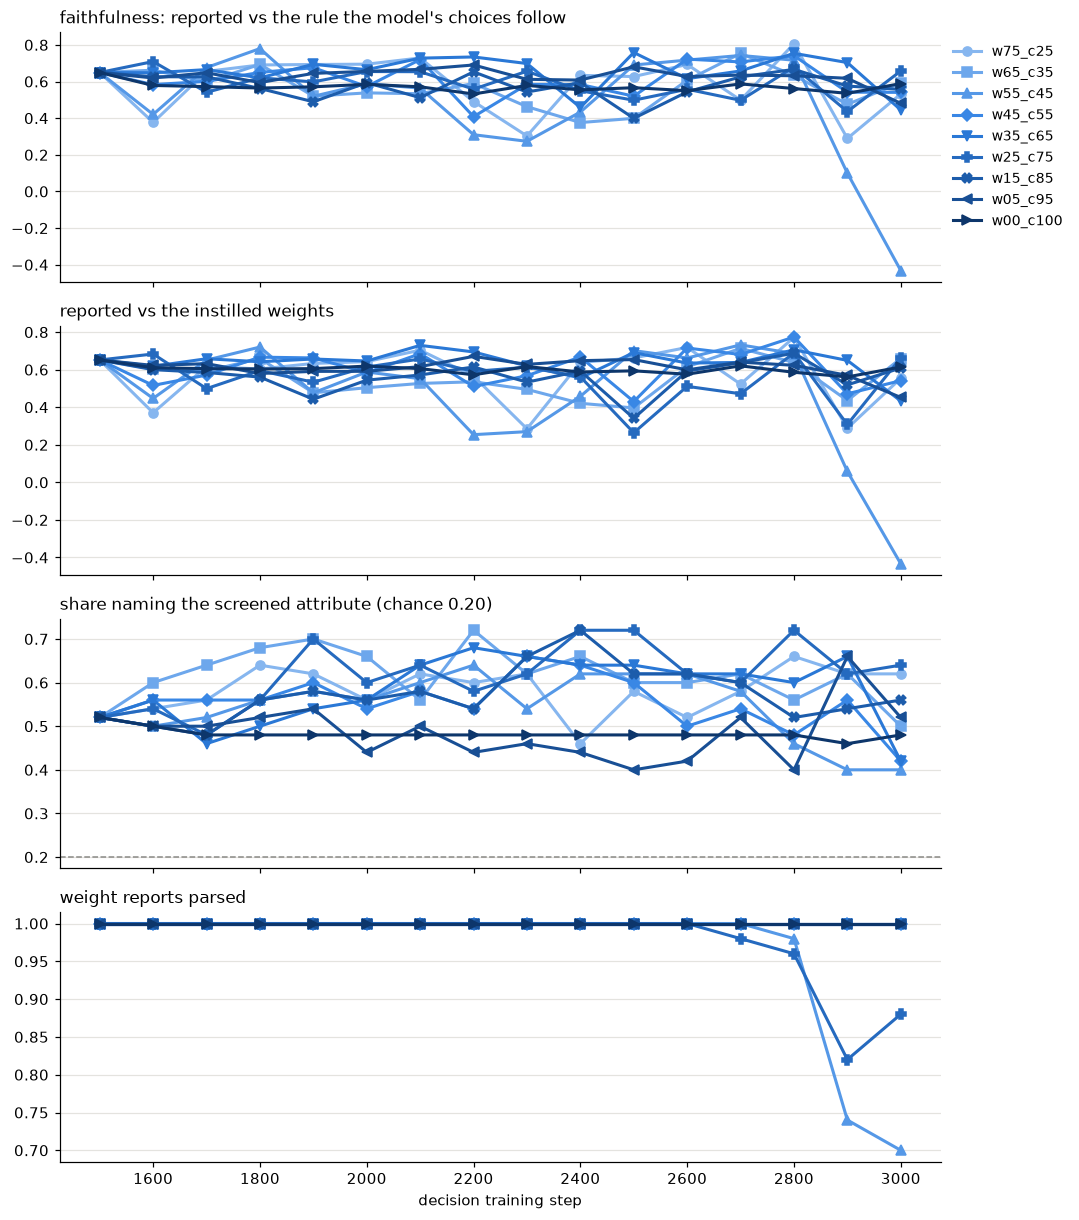

In [13]:
for target in ([SWEEP] if SWEEP else [r for r in RUNS.values() if r]):
    plot_results(target);

## Optional: carry finished runs on further

Each finished run of `SWEEP` continues from its last evaluated checkpoint to `CONTINUE_TO`, under the same run id.
Leave it `None` to skip.

In [ ]:
from src.experiments import continue_sweep

CONTINUE_TO = None           # e.g. 4000
if CONTINUE_TO and SWEEP:
    continue_sweep(SWEEP, to=CONTINUE_TO, hub_repo=HUB_REPO)
else:
    print("skipped: set CONTINUE_TO (and SWEEP) to carry the runs on")